# Milestone 4 | Flight-only Regression

## Objective

This notebook examines how season, airline, scheduled
departure hour, flight distance, and origin airport
are associated with arrival delays.

We use multiple linear regression to estimate these
relationships and evaluate the model through
diagnostic tests.

This model also serves as the baseline for comparison
with Model 2, which includes weather variables.

In [1]:
import pandas as pd

# Load the analysis-ready dataset
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "milestone4_statistical_analysis":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "cleaned" / "analysis_ready_flights.csv"

assert DATA_PATH.exists(), f"File not found: {DATA_PATH}"

flights = pd.read_csv(DATA_PATH)

print("Data file found:", DATA_PATH.exists())

# Check the dataset dimensions
print("Dataset shape:", flights.shape)

# Check the column names
print(flights.columns.tolist())

Data file found: True
Dataset shape: (327346, 34)
['year', 'month', 'day', 'dep_time', 'sched_dep_time', 'dep_delay', 'arr_time', 'sched_arr_time', 'arr_delay', 'carrier', 'flight', 'tailnum', 'origin', 'dest', 'air_time', 'distance', 'hour', 'minute', 'time_hour', 'season', 'scheduled_hour', 'year_weather', 'month_weather', 'day_weather', 'hour_weather', 'temp', 'dewp', 'humid', 'wind_dir', 'wind_speed', 'wind_gust', 'precip', 'pressure', 'visib']


In [2]:
# Check missing values in the Model 1 variables
model1_variables = [
    "arr_delay",
    "season",
    "carrier",
    "scheduled_hour",
    "distance",
    "origin"
]

print(flights[model1_variables].isna().sum())

# Check the categories in each categorical variable
print("\nSeason categories:")
print(flights["season"].value_counts())

print("\nAirlines:")
print(flights["carrier"].nunique())
print(flights["carrier"].value_counts())

print("\nOrigin airports:")
print(flights["origin"].value_counts())

arr_delay         0
season            0
carrier           0
scheduled_hour    0
distance          0
origin            0
dtype: int64

Season categories:
season
Summer    84124
Spring    83594
Fall      82599
Winter    77029
Name: count, dtype: int64

Airlines:
16
carrier
UA    57782
B6    54049
EV    51108
DL    47658
AA    31947
MQ    25037
US    19831
9E    17294
WN    12044
VX     5116
FL     3175
AS      709
F9      681
YV      544
HA      342
OO       29
Name: count, dtype: int64

Origin airports:
origin
EWR    117127
JFK    109079
LGA    101140
Name: count, dtype: int64


In [3]:
# Create a separate dataset for Model 1
model1_data = flights[
    ["arr_delay", "season", "carrier", "scheduled_hour", "distance", "origin"]
].copy()

# Set the reference categories
model1_data["season"] = pd.Categorical(
    model1_data["season"],
    categories=["Winter", "Spring", "Summer", "Fall"]
)

model1_data["carrier"] = pd.Categorical(
    model1_data["carrier"],
    categories=["AA", "AS", "B6", "DL", "EV", "F9", "FL", "HA",
                "MQ", "OO", "UA", "US", "VX", "WN", "YV", "9E"]
)

model1_data["origin"] = pd.Categorical(
    model1_data["origin"],
    categories=["JFK", "LGA", "EWR"]
)

# Convert categorical variables into dummy variables
model1_data = pd.get_dummies(
    model1_data,
    columns=["season", "carrier", "origin"],
    drop_first=True,
    dtype=int
)

# Check the prepared dataset
print("Model 1 dataset shape:", model1_data.shape)
print(model1_data.head())
print("\nData types:")
print(model1_data.dtypes)

Model 1 dataset shape: (327346, 23)
   arr_delay  scheduled_hour  distance  season_Spring  season_Summer  \
0       11.0               5      1400              0              0   
1       20.0               5      1416              0              0   
2       33.0               5      1089              0              0   
3      -18.0               5      1576              0              0   
4      -25.0               6       762              0              0   

   season_Fall  carrier_AS  carrier_B6  carrier_DL  carrier_EV  ...  \
0            0           0           0           0           0  ...   
1            0           0           0           0           0  ...   
2            0           0           0           0           0  ...   
3            0           0           1           0           0  ...   
4            0           0           0           1           0  ...   

   carrier_MQ  carrier_OO  carrier_UA  carrier_US  carrier_VX  carrier_WN  \
0           0           0  

In [4]:
%pip install statsmodels


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [5]:
import statsmodels.api as sm

y = model1_data["arr_delay"]
X = model1_data.drop(columns=["arr_delay"])
X = sm.add_constant(X)

model1 = sm.OLS(y, X).fit()

print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:              arr_delay   R-squared:                       0.058
Model:                            OLS   Adj. R-squared:                  0.058
Method:                 Least Squares   F-statistic:                     918.8
Date:                Tue, 24 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:07:54   Log-Likelihood:            -1.6981e+06
No. Observations:              327346   AIC:                         3.396e+06
Df Residuals:                  327323   BIC:                         3.396e+06
Df Model:                          22                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const            -17.4022      0.427    -40.

## Model 1 Results

Model 1 includes 327,346 flights and explains
approximately 5.8% of the variation in arrival delays.

Winter, American Airlines (AA), and JFK are used
as the reference categories for season, airline,
and origin airport, respectively.

Each regression coefficient represents the estimated
difference in arrival delay while holding the other
predictors constant.

Although the model identifies associations between
flight characteristics and arrival delays, most of
the variation remains unexplained. Additional
diagnostics are needed to evaluate the model.

The following diagnostics evaluate potential multicollinearity among predictors 
and assess the assumptions of the regression model.

In [6]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()

vif_data["Variable"] = X.columns
vif_data["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print(vif_data.sort_values("VIF", ascending=False))

          Variable       VIF
9       carrier_EV  2.953432
15      carrier_UA  2.894629
22      origin_EWR  2.625609
7       carrier_B6  2.478384
8       carrier_DL  2.135957
21      origin_LGA  1.940076
13      carrier_MQ  1.773154
2         distance  1.700524
20      carrier_9E  1.671396
16      carrier_US  1.633225
4    season_Summer  1.555593
3    season_Spring  1.553203
5      season_Fall  1.551934
18      carrier_WN  1.397410
17      carrier_VX  1.210033
11      carrier_FL  1.113943
12      carrier_HA  1.050099
6       carrier_AS  1.042473
10      carrier_F9  1.025024
19      carrier_YV  1.022200
1   scheduled_hour  1.017129
14      carrier_OO  1.001282
0            const  1.000000


### Multicollinearity

Excluding the intercept, all predictor VIF values
were below 5, with the highest value approximately
2.95.

This suggests that multicollinearity is not a major
concern in Model 1. Therefore, all predictors were
retained.

In [7]:
%pip install matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


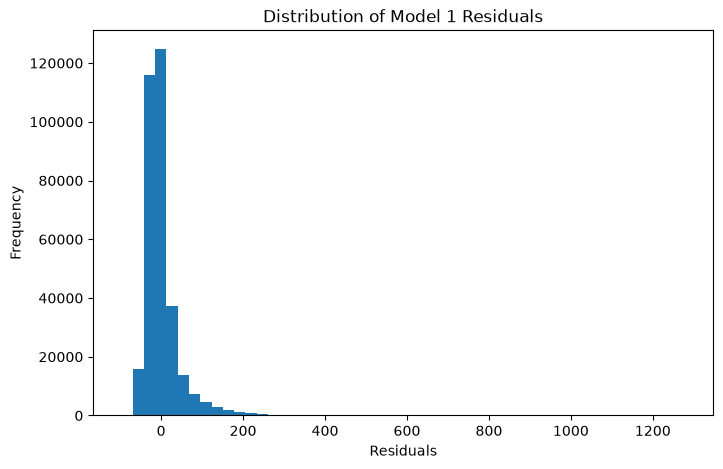

In [8]:
import matplotlib.pyplot as plt

residuals = model1.resid

plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=50)
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Distribution of Model 1 Residuals")
plt.show()

Most of the residuals are close to zero, but there is a long tail on the right side. This means the model has some much larger prediction errors, especially for flights with longer delays.

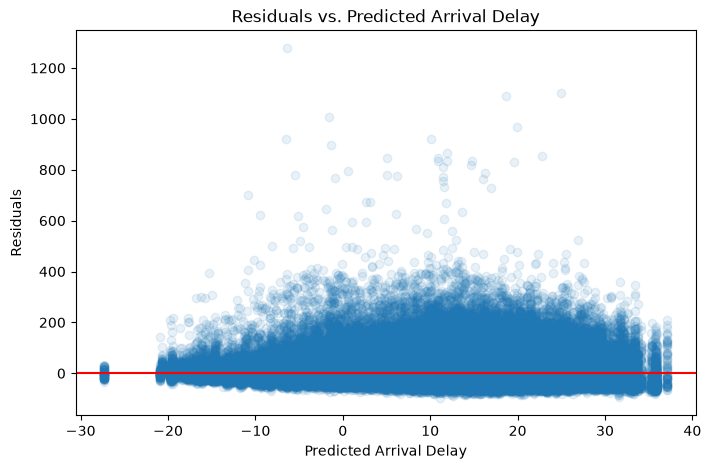

In [9]:
fitted_values = model1.fittedvalues

plt.figure(figsize=(8, 5))
plt.scatter(fitted_values, residuals, alpha=0.1)
plt.axhline(y=0, color="red")
plt.xlabel("Predicted Arrival Delay")
plt.ylabel("Residuals")
plt.title("Residuals vs. Predicted Arrival Delay")
plt.show()

The residuals have different levels of spread across the predicted values, with some very large errors. This suggests that the model's errors are not consistent across all flights.

In [10]:
from statsmodels.stats.diagnostic import het_breuschpagan

bp_test = het_breuschpagan(model1.resid, model1.model.exog)

print("LM Statistic:", bp_test[0])
print("P-value:", bp_test[1])

LM Statistic: 2475.922945759785
P-value: 0.0


### Heteroskedasticity

The Breusch-Pagan test indicated strong evidence
of heteroskedasticity (p < 0.001), meaning that
the residual variance is not constant.

We use HC3 robust standard errors to account for
heteroskedasticity when conducting statistical
inference.

HC3 adjusts standard errors, confidence intervals,
and p-values without changing the regression
coefficients or R-squared. It does not eliminate
heteroskedasticity itself.

In [11]:
model1_robust = model1.get_robustcov_results(cov_type="HC3")

print(model1_robust.summary())

                            OLS Regression Results                            
Dep. Variable:              arr_delay   R-squared:                       0.058
Model:                            OLS   Adj. R-squared:                  0.058
Method:                 Least Squares   F-statistic:                     879.6
Date:                Tue, 24 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:08:35   Log-Likelihood:            -1.6981e+06
No. Observations:              327346   AIC:                         3.396e+06
Df Residuals:                  327323   BIC:                         3.396e+06
Df Model:                          22                                         
Covariance Type:                  HC3                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const            -17.4022      0.402    -43.

We also estimated the regression using HC3 robust standard errors to account for heteroskedasticity in the residuals. The regression coefficients and R-squared remained unchanged, while the standard errors, confidence intervals, and p-values were adjusted. The model still explains approximately 5.8% of the variation in arrival delays.

In [12]:
from statsmodels.stats.outliers_influence import OLSInfluence

influence = OLSInfluence(model1)

cooks_distance = influence.cooks_distance[0]

print("Highest Cook's Distance:", cooks_distance.max())
print("Flights with Cook's Distance above 4/n:",
      (cooks_distance > 4 / len(model1_data)).sum())

Highest Cook's Distance: 0.11174929799750824
Flights with Cook's Distance above 4/n: 12321


Cook's Distance identified 12,321 flights above the 4/n reference threshold. This threshold is used to flag observations that may have a greater influence on the regression results, but exceeding it does not necessarily mean an observation is invalid or should be removed. We retained these flights in the dataset to preserve the original sample and avoid removing observations without further justification.

In [13]:
top_influence = pd.DataFrame({
    "Cook's Distance": cooks_distance,
    "Flight Index": model1_data.index
})

top_influence = top_influence.sort_values(
    "Cook's Distance", ascending=False
).head(10)

print(top_influence)

        Cook's Distance  Flight Index
7008           0.111749          7008
116533         0.023135        116533
236112         0.015536        236112
297644         0.011498        297644
25109          0.008361         25109
46476          0.006251         46476
138797         0.005041        138797
240784         0.003970        240784
208827         0.003616        208827
208988         0.002561        208988


In [14]:
top_flights = flights.loc[top_influence["Flight Index"], [
    "month", "day", "carrier", "flight",
    "origin", "dest", "arr_delay", "dep_delay", "distance"
]]

print(top_flights)

        month  day carrier  flight origin dest  arr_delay  dep_delay  distance
7008        1    9      HA      51    JFK  HNL     1272.0     1301.0      4983
116533      2   10      F9     835    LGA  DEN      834.0      853.0      1620
236112      6   22      OO    4528    EWR  DTW      157.0      131.0       488
297644      8   28      OO    5568    LGA  CLE      140.0      154.0       419
25109       1   30      OO    8500    LGA  ORD      107.0       67.0       733
46476      10   22      YV    2693    LGA  CLT      381.0      387.0       544
138797      3    8      F9     797    LGA  DEN      410.0      430.0      1620
240784      6   27      YV    2751    LGA  CLT      328.0      340.0       544
208827      5   23      F9     507    LGA  DEN      345.0      272.0      1620
208988      5   23      F9     837    LGA  DEN      300.0      308.0      1620


In [15]:
weather_columns = [
    col for col in flights.columns
    if any(word in col.lower() for word in [
        "temp", "humid", "wind", "precip", "pressure",
        "visibility", "weather", "rain", "snow", "cloud"
    ])
]

print(weather_columns)

['year_weather', 'month_weather', 'day_weather', 'hour_weather', 'temp', 'humid', 'wind_dir', 'wind_speed', 'wind_gust', 'precip', 'pressure']


In [16]:
weather_cols = [
    "temp", "humid", "wind_dir", "wind_speed",
    "wind_gust", "precip", "pressure"
]

missing_weather = pd.DataFrame({
    "Missing Values": flights[weather_cols].isna().sum(),
    "Missing %": (flights[weather_cols].isna().mean() * 100).round(2)
})

print(missing_weather)

            Missing Values  Missing %
temp                  1544       0.47
humid                 1544       0.47
wind_dir              9574       2.92
wind_speed            1605       0.49
wind_gust           249912      76.34
precip                1527       0.47
pressure             36142      11.04


In [17]:
weather_without_gust = [
    "temp", "humid", "wind_dir",
    "wind_speed", "precip", "pressure"
]

weather_with_gust = weather_without_gust + ["wind_gust"]

print("Flights with all weather data (excluding gust):",
      flights[weather_without_gust].dropna().shape[0])

print("Flights with all weather data (including gust):",
      flights[weather_with_gust].dropna().shape[0])

print("Total flights:", len(flights))

Flights with all weather data (excluding gust): 284550
Flights with all weather data (including gust): 72734
Total flights: 327346


In [18]:
model2_cols = [
    "arr_delay", "season", "carrier", "scheduled_hour",
    "distance", "origin", "temp", "humid",
    "wind_speed", "precip", "pressure", "visib"
]

model2_sample = flights[model2_cols].dropna()

print("Model 2 complete-case sample:", len(model2_sample))
print("Flights excluded:", len(flights) - len(model2_sample))

Model 2 complete-case sample: 291140
Flights excluded: 36206


## Common Sample for Model Comparison

Model 2 requires complete observations for six
additional weather variables.

After excluding 36,206 flights with missing values
in the selected variables, 291,140 flights remain
for the model comparison.

Model 1 will be estimated again using this same
sample so that differences in model performance
can be evaluated fairly.

In [19]:
print(model2_sample.shape)

(291140, 12)


In [20]:
model1_comparison_data = model2_sample[
    ["arr_delay", "season", "carrier", "scheduled_hour",
     "distance", "origin"]
].copy()

model1_comparison_data["season"] = pd.Categorical(
    model1_comparison_data["season"],
    categories=["Winter", "Spring", "Summer", "Fall"]
)

model1_comparison_data["carrier"] = pd.Categorical(
    model1_comparison_data["carrier"],
    categories=["AA", "AS", "B6", "DL", "EV", "F9", "FL", "HA",
                "MQ", "OO", "UA", "US", "VX", "WN", "YV", "9E"]
)

model1_comparison_data["origin"] = pd.Categorical(
    model1_comparison_data["origin"],
    categories=["JFK", "LGA", "EWR"]
)

model1_comparison_data = pd.get_dummies(
    model1_comparison_data,
    columns=["season", "carrier", "origin"],
    drop_first=True,
    dtype=int
)

y_comparison = model1_comparison_data["arr_delay"]
X_comparison = model1_comparison_data.drop(columns=["arr_delay"])
X_comparison = sm.add_constant(X_comparison)

model1_comparison = sm.OLS(y_comparison, X_comparison).fit()

model1_comparison_robust = model1_comparison.get_robustcov_results(
    cov_type="HC3"
)

print(model1_comparison_robust.summary())



                            OLS Regression Results                            
Dep. Variable:              arr_delay   R-squared:                       0.054
Model:                            OLS   Adj. R-squared:                  0.054
Method:                 Least Squares   F-statistic:                     707.1
Date:                Tue, 24 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:08:38   Log-Likelihood:            -1.4929e+06
No. Observations:              291140   AIC:                         2.986e+06
Df Residuals:                  291117   BIC:                         2.986e+06
Df Model:                          22                                         
Covariance Type:                  HC3                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const            -17.4458      0.402    -43.

In [21]:
print(model1_comparison.nobs)
print(model1_comparison.rsquared)

291140.0
0.05395247786987345


### Model 1 on the Common Sample

Using the common sample of 291,140 flights,
Model 1 explains approximately 5.4% of the
variation in arrival delays.

Holding other predictors constant, a one-hour
increase in scheduled departure hour is associated
with approximately 1.45 additional minutes of
arrival delay.

The decrease in R-squared from 0.058 to 0.054
reflects the change in the analysis sample rather
than the addition of weather variables.

The same sample will be used to evaluate Model 2.

### Regression Notebook Summary

We first ran Model 1 using 327,346 flights. The model explained approximately 5.8% of the variation in arrival delays. This means that the variables included in Model 1 explain a relatively small part of the differences in arrival delays. Other factors not included in the model may also affect flight delays.

We checked the model's assumptions and found evidence of heteroskedasticity, meaning the variance of the residuals was not constant. We also identified 12,321 flights above the Cook's Distance reference threshold. These observations may have greater influence on the regression results, but we kept them in the dataset because exceeding the threshold does not automatically mean they should be removed.

We also used HC3 robust standard errors to account for heteroskedasticity when evaluating statistical significance. This adjusted the standard errors, confidence intervals, and p-values without changing the regression coefficients or R-squared.

We then ran Model 1 again using the 291,140 flights that had complete weather data. This allows us to compare Model 1 and Model 2 using the same flights. With this smaller sample, the model explained approximately 5.4% of the variation in arrival delays. The decrease in R-squared reflects the change in the sample used for the analysis.